# Pakistan House Price Prediction (Zameen.com data)

**Goal:** predict the price of a house that is *for sale* in Pakistan.

**Plan of this project**
1. Load and check the data
2. Preprocessing (clean the data)
3. EDA (understand the data with plots)
4. Feature selection (choose the inputs for the model)
5. Model 1: Linear Regression (baseline)
6. Model 2: to be added (to beat the baseline)
7. Compare the models

**Main learning of this project:** compare 2 models and evaluate them in a fair way.

In [1]:
pip show scikit-learn

Name: scikit-learn
Version: 1.9.1
Summary: A set of python modules for machine learning and data mining
Home-page: 
Author: 
Author-email: 
License: 
Location: c:\Users\LENOVO\Desktop\Pakistan_real_estate_price_pridiction\venv\Lib\site-packages
Requires: joblib, narwhals, numpy, scipy, threadpoolctl
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [1]:
# libraries for data
import pandas as pd
import numpy as np

# library for plots
import matplotlib.pyplot as plt

# libraries for machine learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

## 1. Load and Check the Data

Here we read the file and look at it for the first time: size, column types, missing values and duplicates.

In [2]:
# read the csv (columns are separated by ;)
df = pd.read_csv("Property.csv", sep=";")

# size of the data and first 5 rows
print(df.shape)
df.head()

(191393, 17)


,property_id,location_id,page_url,property_type,price,location,city,province_name,latitude,longitude,baths,area,purpose,bedrooms,date_added,agency,agent
0,347795,8,https://www.zameen.com/Property/lahore_model_t...,House,220000000,Model Town,Lahore,Punjab,31.483869,74.325686,0,6 Kanal,For Sale,0,07-17-2019,Real Biz International,Usama Khan
1,482892,48,https://www.zameen.com/Property/lahore_multan_...,House,40000000,Multan Road,Lahore,Punjab,31.431593,74.179980,5,1 Kanal,For Sale,5,10-06-2018,Khan Estate,mohsinkhan and B
2,555962,75,https://www.zameen.com/Property/eden_eden_aven...,House,9500000,Eden,Lahore,Punjab,31.499348,74.416959,0,9 Marla,For Sale,3,07-03-2019,Shahum Estate 2,"Babar Hameed, Raja Omar"
3,562843,3821,https://www.zameen.com/Property/gulberg_2_gulb...,House,125000000,Gulberg,Lahore,Punjab,31.522069,74.355512,7,1 Kanal,For Sale,8,04-04-2019,NaN,NaN
4,686990,3522,https://www.zameen.com/Property/allama_iqbal_t...,House,21000000,Allama Iqbal Town,Lahore,Punjab,31.506483,74.286017,5,11 Marla,For Sale,6,04-04-2019,NaN,NaN


In [3]:
# column types and non-null counts
df.info()

# missing values in each column
print(df.isnull().sum())

# fully duplicate rows
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 191393 entries, 0 to 191392
Data columns (total 17 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   property_id    191393 non-null  int64  
 1   location_id    191393 non-null  int64  
 2   page_url       191393 non-null  str    
 3   property_type  191393 non-null  str    
 4   price          191393 non-null  int64  
 5   location       191393 non-null  str    
 6   city           191393 non-null  str    
 7   province_name  191393 non-null  str    
 8   latitude       191393 non-null  float64
 9   longitude      191393 non-null  float64
 10  baths          191393 non-null  int64  
 11  area           191393 non-null  str    
 12  purpose        191393 non-null  str    
 13  bedrooms       191393 non-null  int64  
 14  date_added     191393 non-null  str    
 15  agency         144014 non-null  str    
 16  agent          144013 non-null  str    
dtypes: float64(2), int64(5), str(10)
memory 

property_id          0
location_id          0
page_url             0
property_type        0
price                0
location             0
city                 0
province_name        0
latitude             0
longitude            0
baths                0
area                 0
purpose              0
bedrooms             0
date_added           0
agency           47379
agent            47380
dtype: int64


Duplicate rows: 0


**What we see:** only `agency` and `agent` have missing values, and we will not use them. There are no duplicate rows.

## 2. Preprocessing

Clean the data step by step so the model learns from correct values.

### 2.1 Keep only "For Sale" rows
The data has rent and sale listings. Their prices are very different, so we use only sale.

In [4]:
# types of purpose
print(df["purpose"].value_counts())

# keep only sale rows (copy so the original df is safe)
df_sale = df[df["purpose"] == "For Sale"].copy()
print(df_sale.shape)

# same property_id repeated?
print("Repeated property_id:", df_sale["property_id"].duplicated().sum())

purpose
For Sale    127018
For Rent     64375
Name: count, dtype: int64
(127018, 17)
Repeated property_id: 0


### 2.2 Remove very low prices
Some prices are too small to be real (for example 1 or 8 PKR). They are typing mistakes or rent prices.

In [5]:
# smallest and largest prices
print(df_sale["price"].nsmallest(10))
print(df_sale["price"].nlargest(10))

# how many rows are below 500,000
print("Below 500,000:", (df_sale["price"] < 500_000).sum())

97464     0
140353    0
10013     1
78718     1
165134    1
165404    1
170826    1
172059    1
177437    1
186642    1
Name: price, dtype: int64
90714     2000000000
61464     1450000000
72863     1430000000
81652     1350000000
15564     1270000000
39        1250000000
78587     1250000000
90        1200000000
58573     1000000000
101184    1000000000
Name: price, dtype: int64
Below 500,000: 123


***Dropped price < 500,000: 123 rows, mostly rent-sized or typo prices (1, 8, 16,000 PKR)***

In [6]:
# keep only prices of 500,000 or more
df_sale = df_sale[df_sale["price"] >= 500_000].copy()
print(df_sale.shape)

(126895, 17)


### 2.3 Change area to one number (marla)
`area` is text like "6 Kanal". The model needs numbers, so we change everything to **marla** (1 Kanal = 20 Marla).

In [7]:
# units we have in area
print(df_sale["area"].str.split().str[-1].value_counts())

# number part of area (remove comma, for example 4,450)
num = df_sale["area"].str.split().str[0].str.replace(",", "").astype(float)

# 1 Kanal = 20 Marla
factor = df_sale["area"].str.split().str[-1].map({"Marla": 1, "Kanal": 20})

# area in marla
df_sale["area_marla"] = num * factor

# check: no missing value after map
print("Missing area_marla:", df_sale["area_marla"].isna().sum())

area
Marla    107231
Kanal     19664
Name: count, dtype: int64


Missing area_marla: 0


### 2.4 Remove zero area and make price per marla
Price per marla helps us find fake prices, because it compares houses of different sizes. We cannot divide by zero, so zero-area rows are removed first.

In [8]:
# rows with zero area
print("Zero area rows:", (df_sale["area_marla"] == 0).sum())

# remove them
df_sale = df_sale[df_sale["area_marla"] > 0].copy()

# price per marla
df_sale["price_per_marla"] = df_sale["price"] / df_sale["area_marla"]
print(df_sale["price_per_marla"].describe())

Zero area rows: 11
count    1.268840e+05
mean     2.313672e+06
std      5.257733e+06
min      1.161305e+02
25%      1.500000e+06
50%      2.000000e+06
75%      2.675000e+06
max      1.500000e+09
Name: price_per_marla, dtype: float64


### 2.5 Remove outliers for each property type
Max price per marla is far above the median, so a few values are wrong. Farm houses are cheaper per marla than houses, so we cut the extreme 1% on each side **inside each property type**, not for all rows together.

In [9]:
# lower and upper limit for each property type (1% and 99%)
low = df_sale.groupby("property_type")["price_per_marla"].transform(lambda s: s.quantile(0.01))
high = df_sale.groupby("property_type")["price_per_marla"].transform(lambda s: s.quantile(0.99))

# keep rows inside the limits
rows_before = len(df_sale)
df_sale = df_sale[df_sale["price_per_marla"].between(low, high)].copy()
print("Rows removed:", rows_before - len(df_sale))

# check the new spread
print(df_sale["price_per_marla"].describe())

Rows removed: 2528
count    1.243560e+05
mean     2.229696e+06
std      1.108272e+06
min      2.343750e+04
25%      1.500000e+06
50%      2.000000e+06
75%      2.656250e+06
max      7.812500e+06
Name: price_per_marla, dtype: float64


### 2.6 Fix zeros in baths and bedrooms
A house with 0 baths is not real, so 0 means "missing". We fill it with the median of the same property type. We also keep a 0/1 column that remembers which rows were filled.

In [10]:
# baths: mark the zeros, make them NaN, fill with median of property type
df_sale["baths_missing"] = (df_sale["baths"] == 0).astype(int)
df_sale["baths"] = df_sale["baths"].replace(0, np.nan)
df_sale["baths"] = df_sale.groupby("property_type")["baths"].transform(lambda s: s.fillna(s.median()))

# bedrooms: same steps
df_sale["bedrooms_missing"] = (df_sale["bedrooms"] == 0).astype(int)
df_sale["bedrooms"] = df_sale["bedrooms"].replace(0, np.nan)
df_sale["bedrooms"] = df_sale.groupby("property_type")["bedrooms"].transform(lambda s: s.fillna(s.median()))

# check: no missing values left
print(df_sale[["baths", "bedrooms"]].isna().sum())

baths       0
bedrooms    0
dtype: int64


*Note:* here the median is taken before the train/test split, which lets a little test information in. For this project it is fine. A cleaner way is to do it inside the pipeline after the split.

### 2.7 Drop columns we do not need
These columns do not help the model (links, ids, names, or the same information as another column).

In [11]:
# columns that are not useful for prediction
cols_to_drop = ["page_url", "property_id", "location_id", "purpose", "province_name", "agency", "agent"]
df_sale = df_sale.drop(columns=cols_to_drop)
print(df_sale.columns.tolist())

['property_type', 'price', 'location', 'city', 'latitude', 'longitude', 'baths', 'area', 'bedrooms', 'date_added', 'area_marla', 'price_per_marla', 'baths_missing', 'bedrooms_missing']


## 3. EDA (Exploratory Data Analysis)

Plots help us decide how to train the model. We check three things: the shape of price, price vs area, and price by city.

### 3.1 Is price skewed?

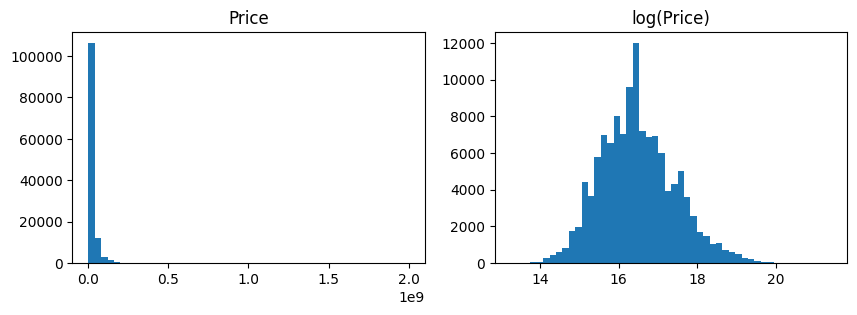

In [12]:
# left: raw price, right: log of price
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(df_sale["price"], bins=50)
ax[0].set_title("Price")
ax[1].hist(np.log1p(df_sale["price"]), bins=50)
ax[1].set_title("log(Price)")
plt.show()

**What we see:** raw price is skewed (many cheap houses, a few very expensive ones). After `log` it looks like a bell shape. So we will **train on log(price)** and change back to PKR for reporting.

### 3.2 Does price grow with area?

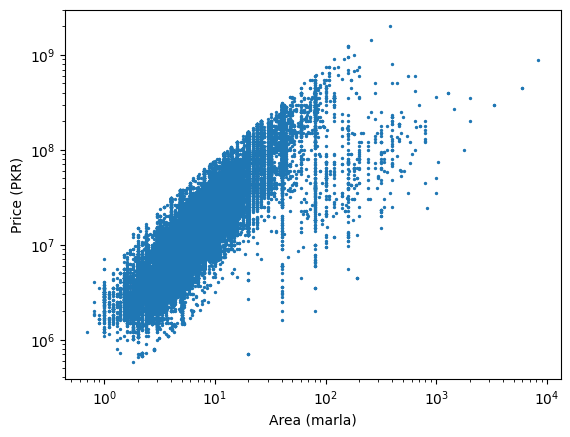

In [13]:
# both axes use log scale so big values do not squash the small ones
plt.scatter(df_sale["area_marla"], df_sale["price"], s=2)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Area (marla)")
plt.ylabel("Price (PKR)")
plt.show()

**What we see:** price goes up when area goes up, so area is a strong feature. A few big plots (farm houses) sit below the main band because they are cheaper per marla.

### 3.3 Price by city

city
Faisalabad     9500000.0
Rawalpindi    11000000.0
Karachi       12500000.0
Islamabad     16000000.0
Lahore        16000000.0
Name: price, dtype: float64


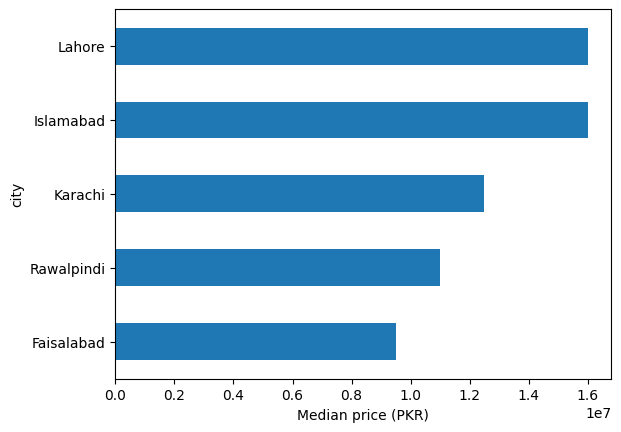

In [14]:
# median price of each city
city_median = df_sale.groupby("city")["price"].median().sort_values()
print(city_median)

city_median.plot(kind="barh")
plt.xlabel("Median price (PKR)")
plt.show()

**What we see:** Lahore and Islamabad are the most expensive, Faisalabad is the cheapest. So `city` is an important feature.

### 3.4 How many values do the text columns have?

In [15]:
# number of different values in each text column
print(df_sale[["city", "location", "property_type"]].nunique())

city                5
location         1443
property_type       7
dtype: int64


**What we see:** `location` has more than 1,000 values. One-hot encoding would make too many columns, so we fix this in the next section.

## 4. Feature Selection and Preparation

Here we choose the inputs (`X`) and the target (`y`), then prepare them for the model.

### 4.1 Group rare locations
Locations with fewer than 50 listings are replaced by "Other". The model cannot learn much from a location that has only a few rows.

In [16]:
# number of listings in each location
counts = df_sale["location"].value_counts()

# locations with at least 50 listings
common = counts[counts >= 50].index

# all other locations become "Other"
df_sale["location"] = df_sale["location"].where(df_sale["location"].isin(common), "Other")

# check: common locations + 1 ("Other")
print("Locations now:", df_sale["location"].nunique())

Locations now: 249


### 4.2 Log of area
Linear Regression draws straight lines. Without log, a few huge areas (up to 8,000+ marla) push the line too far and give crazy predictions. Log makes the area scale smaller. This was a bug we found while testing the first version of the model.

In [17]:
# log of area
df_sale["log_area"] = np.log1p(df_sale["area_marla"])

### 4.3 Choose inputs (X) and target (y)

**Not used on purpose:**
- `price_per_marla`: it is made from `price`, so it would give the answer to the model (**data leakage**)
- `area` (text) and `area_marla`: replaced by `log_area`
- `date_added`: needs more work, maybe later

In [18]:
# input columns
features = ["city", "location", "property_type", "latitude", "longitude",
            "baths", "bedrooms", "log_area", "baths_missing", "bedrooms_missing"]
X = df_sale[features]

# target: log of price
y = np.log1p(df_sale["price"])

### 4.4 Train / test split
80% of the data is for learning and 20% is kept hidden for the final test. `random_state=42` gives the same split every time.

In [19]:
# split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

# check: no missing values in the training inputs
print("Missing values:", X_train.isna().sum().sum())

(99484, 10) (24872, 10)
Missing values: 0


### 4.5 Encode text columns
Models need numbers. `OneHotEncoder` makes one 0/1 column for each value (Karachi, Lahore, ...). `ColumnTransformer` applies it only to the text columns and lets the number columns pass.

In [20]:
# text columns
cat_cols = ["city", "location", "property_type"]

# one-hot for text columns, number columns stay the same
prep = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)],
    remainder="passthrough",
)

## 5. Model Evaluation Setup

We use the **same function for every model**, so the comparison is fair. Models predict log(price), so we change back to PKR first.

- **R2 (log):** how much of the price changes the model explains (1 is perfect)
- **MAE (PKR):** average error in rupees. A few huge errors can make it big.
- **Median error (PKR):** the typical error. It is not affected by a few huge errors.

In [21]:
def evaluate(name, y_true_log, pred_log):
    # change from log back to PKR
    y_true = np.expm1(y_true_log)
    pred = np.expm1(pred_log)

    # return the three scores
    return {
        "model": name,
        "R2 (log)": r2_score(y_true_log, pred_log),
        "MAE (PKR)": mean_absolute_error(y_true, pred),
        "Median error (PKR)": np.median(np.abs(y_true - pred)),
    }

# we keep the scores of all models here
results = []

## 6. Model 1: Linear Regression (Baseline)

A simple model first. Its score is the number every better model must beat. We put preprocessing and model in one `Pipeline` so the same steps run for train and test data.

In [22]:
# pipeline: preprocessing + model
lr_pipe = Pipeline([("prep", prep), ("model", LinearRegression())])

# learn from training data
lr_pipe.fit(X_train, y_train)

# predict on test data
lr_pred = lr_pipe.predict(X_test)

# save the scores
results.append(evaluate("Linear Regression", y_test, lr_pred))
pd.DataFrame(results).round(2)

,model,R2 (log),MAE (PKR),Median error (PKR)
0,Linear Regression,0.89,5593222.14,2203111.29
